# MinHash Sequence Similarity

Estimate k-mer set similarity from the minimum keys across repeated random orderings.

For a uniformly random ordering, the minimum of two nonempty sets agrees with probability equal to their Jaccard similarity. The tiny observed universe here permits exact random permutations. Practical sequence sketchers use hashes and more economical sketches.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import kmers, rng_dna

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Exact Jaccard 0.819 | 400-sketch estimate 0.820


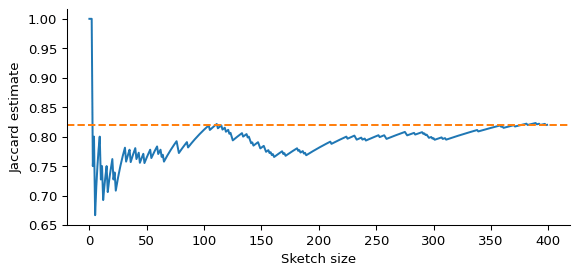

In [2]:
rng = np.random.default_rng(17)
a = rng_dna(rng, 240)
b = a[:80] + rng_dna(rng, 25) + a[105:]
A = set(kmers(a, 5))
B = set(kmers(b, 5))
universe = sorted(A | B)
exact = len(A & B) / len(A | B)
labels = {word: i for i, word in enumerate(universe)}
ia = [labels[x] for x in A]
ib = [labels[x] for x in B]
same = []
for t in range(400):
    rank = rng.permutation(len(universe))
    same.append(rank[ia].min() == rank[ib].min())
est = np.cumsum(same) / np.arange(1, 401)
print(f"Exact Jaccard {exact:.3f} | 400-sketch estimate {est[-1]:.3f}")
plt.figure(figsize=(6.2, 3))
plt.plot(est)
plt.axhline(exact, ls="--", color="tab:orange")
plt.xlabel("Sketch size")
plt.ylabel("Jaccard estimate")
plt.tight_layout()
plt.show()

## Interpreting the result

The estimate fluctuates even with unchanged sequences. Finite sketch error and biological sampling error are separate.

## Exercise

Compare variation across seeds at sketch sizes 20 and 400.

## References

[Ondov et al., Mash (2016)](https://doi.org/10.1186/s13059-016-0997-x)